# Different ways of Detecting and Handling Outliers in a dataset

In [7]:
# Import

import sklearn
from sklearn.datasets import load_diabetes
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Visualizing and Removing Outliers using Box Plots

- Box plots hels to visualize how data is distributed using quartiles.
- points outside the whiskers of the box plot are cosnidered outliers


In [ ]:
# Creating our dataset
diabetes = load_diabetes()
# print(diabetes, diabetes.data)

column_name = diabetes.feature_names
# print(column_name)

df_diabetics = pd.DataFrame(diabetes.data, columns=column_name)

df_diabetics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB


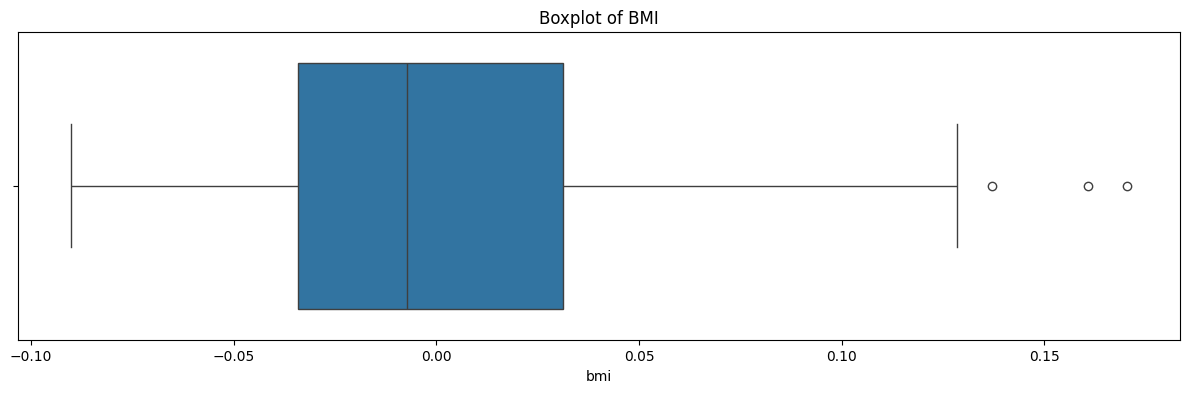

In [13]:
# Visualizing it in a boxplot for BMI column

plt.figure(figsize=(15, 4))
sns.boxplot(x=df_diabetics['bmi'])
plt.title('Boxplot of BMI')
plt.show()

- We can conclude that our BMI column has outliers based on the points appearing outside the box plot's whiskers.

### Removing the outliers from the BMI column

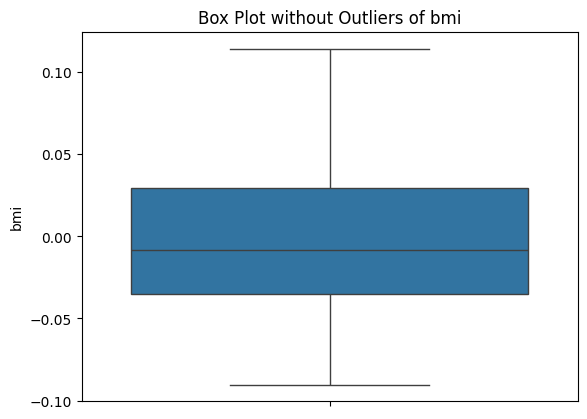

In [15]:
# Removing the outliers and replacing them with a predefined threshold.

# print(df_diabetics[df_diabetics['bmi'] <= 0.12])

def outlier_removal_boxplot(df, column, threshold):
    removed_outliers = df[df[column] <= threshold]

    sns.boxplot(removed_outliers[column])
    plt.title(f'Box Plot without Outliers of {column}')
    plt.show()
    return removed_outliers

threshold_value = 0.12

no_outliers = outlier_removal_boxplot(df_diabetics, 'bmi', threshold_value)


          age       sex       bmi        bp        s1        s2        s3  \
0    0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1   -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2    0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3   -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4    0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   
..        ...       ...       ...       ...       ...       ...       ...   
437  0.041708  0.050680  0.019662  0.059744 -0.005697 -0.002566 -0.028674   
438 -0.005515  0.050680 -0.015906 -0.067642  0.049341  0.079165 -0.028674   
439  0.041708  0.050680 -0.015906  0.017293 -0.037344 -0.013840 -0.024993   
440 -0.045472 -0.044642  0.039062  0.001215  0.016318  0.015283 -0.028674   
441 -0.045472 -0.044642 -0.073030 -0.081413  0.083740  0.027809  0.173816   

           s4        s5        s6  
0   -0.002592  0.019907 -0.017646  
1  